# Null model for mutation multiplicity

Same analysis as in Good et al. 2017:

* The genome is divided in regions (genes, or intergenic regions)
* We count the number of independent mutations in each region (= multiplicity)
* We do the same for a null model where mutations land uniformly along the genome, so each region is hit in proportion to its length (simulated, because overlapping genes make the exact calculation tricky)
* We compare the number of regions with multiplicity ≥ m in the data and in the null

This replaces the earlier R version, which drew intergenic mutations of the null model onto **genes**: its footprint table dropped every context containing `/`, which removes all intergenic regions. Here each class of mutation is compared with a null built from regions of the same class.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FixedLocator, NullFormatter

DATA = Path('../../../datasets/genomics')
PLOTS = Path('Plots')
(PLOTS / 'PDF').mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(2025)

def read_tsv(path, **kw):
    # Mirror R's read.csv: only the literal string 'NA' is missing, empty strings stay empty
    return pd.read_csv(path, sep='\t', keep_default_na=False, na_values=['NA'], **kw)

## Data

In [2]:
position_to_context = read_tsv(DATA / '04_gene_attribution/intermediate/position_to_context.tsv', encoding='utf-8-sig')
tid_to_mutator_bg = read_tsv(DATA / '06_mutators/results/tid_to_mutator_bg.tsv')
v = read_tsv(DATA / '04_gene_attribution/results/v.tsv').merge(tid_to_mutator_bg, on=['pop', 'tid'], how='left')

# De-evolution genes (high multiplicities because they're scars from domestication)
domestication_scars = ['prfB', 'rpsG', 'glyQ']
non_mutators = ['None', 'Reverted', 'pMutS']

# Footprint (bp) of each region of the chromosome, summed over its parts (a few regions are split, e.g. across the origin)
chrom = position_to_context[position_to_context.chrom == 'U00096'].assign(length=lambda d: d.end - d.start + 1)
is_intergenic = chrom.target_type == 'intergenic'

# Genes: single, non-overlapping genes (as in the R version)
gene_footprint = (chrom[~is_intergenic & ~chrom.context.str.contains('|', regex=False)]
                  .groupby('context').length.sum().sort_index())
# Intergenic regions (named 'upstream_gene/downstream_gene')
intergenic_footprint = chrom[is_intergenic].groupby('context').length.sum().sort_index()

print(f'{len(gene_footprint)} genes, {gene_footprint.sum():,} bp')
print(f'{len(intergenic_footprint)} intergenic regions, {intergenic_footprint.sum():,} bp')

4570 genes, 4,083,818 bp
3750 intergenic regions, 495,967 bp


## Observed multiplicities

* Intragenic: non-synonymous SNPs on the chromosome, excluding the domestication scars
* Intergenic: all intergenic mutations, excluding the fimE/fimA switch (fimS), which may not be "natural" mutations

In [3]:
def notna(*cols):
    return np.logical_and.reduce([c.notna() for c in cols])

is_mutator = ~v.mutator_bg.isin(non_mutators)  # NA background counts as mutator, as in R's !(x %in% y)

intragenic = (
    (v.chrom == 'U00096')
    & notna(v.target_type) & (v.target_type != 'intergenic')
    & (v.type == 'SNP')
    & notna(v.aa_ref, v.aa_alt) & (v.aa_ref != v.aa_alt)
    & ~v.context.isin(domestication_scars)
)
intergenic = (v.target_type == 'intergenic') & (v.context != 'fimE/fimA')

sets = {
    ('intragenic', 'non-mutators'): (v[intragenic & ~is_mutator], gene_footprint),
    ('intragenic', 'mutators'):     (v[intragenic & is_mutator],  gene_footprint),
    ('intergenic', 'non-mutators'): (v[intergenic & ~is_mutator], intergenic_footprint),
    ('intergenic', 'mutators'):     (v[intergenic & is_mutator],  intergenic_footprint),
}

max_n = 20  # max multiplicity to consider
n_values = np.arange(max_n + 1)

def cumulative_counts(mult):
    """Number of regions with multiplicity >= n, for n = 0..max_n."""
    counts = np.bincount(np.minimum(mult, max_n), minlength=max_n + 1)
    return counts[::-1].cumsum()[::-1]

observed = {}
for key, (muts, _) in sets.items():
    mult = muts.groupby('context').tid.nunique()
    observed[key] = mult
    top = ', '.join(f'{c} ({m})' for c, m in mult.sort_values(ascending=False).head(5).items())
    print(f'{key[0]:>10}, {key[1]:<12}: {mult.sum():>4} mutations in {len(mult):>4} regions; top: {top}')

intragenic, non-mutators:  581 mutations in  462 regions; top: rpoD (10), fimH (8), sdaC (7), sspA (6), lrp (5)
intragenic, mutators    : 2777 mutations in 1810 regions; top: rhsC (11), dnaE (9), fliF (8), ybbP (7), ptrA (7)
intergenic, non-mutators:  271 mutations in  215 regions; top: yohP/dusC (8), ompF/asnS (5), fabF/pabC (4), glyQ/ysaB (4), yhaC/rnpB (3)
intergenic, mutators    :  599 mutations in  491 regions; top: ycdU/serX (10), rclR/ykgE (4), atpI/rsmG (4), ycgV/ychF (4), nanC/fimB (4)


## Null distributions

Each simulation drops the observed number of mutations onto the regions of the same class, with probabilities proportional to their footprints.

In [4]:
n_simulations = 10_000

null = {}
for key, (muts, footprint) in sets.items():
    n_observed = observed[key].sum()
    p = (footprint / footprint.sum()).to_numpy()
    simulated = rng.multinomial(n_observed, p, size=n_simulations)          # simulations x regions
    cumulative = np.array([cumulative_counts(s) for s in simulated])       # simulations x n_values
    null[key] = pd.DataFrame({
        'mult': n_values,
        'median': np.median(cumulative, axis=0),
        'p5': np.quantile(cumulative, 0.05, axis=0),
        'p95': np.quantile(cumulative, 0.95, axis=0),
        'obs': cumulative_counts(observed[key].to_numpy()),
    })

pd.concat({f'{k[0]}, {k[1]}': d.set_index('mult').loc[1:12] for k, d in null.items()}, axis=1).round(1)

intragenic, non-mutators                    intragenic, mutators          \
                       median     p5    p95  obs               median      p5   
mult                                                                            
1                       529.0  518.0  539.0  462               1870.0  1840.0   
2                        48.0   39.0   57.0   70                630.0   608.0   
3                         4.0    1.0    7.0   21                193.0   176.0   
4                         0.0    0.0    1.0   11                 58.0    47.0   
5                         0.0    0.0    0.0    6                 17.0    11.0   
6                         0.0    0.0    0.0    4                  5.0     2.0   
7                         0.0    0.0    0.0    3                  2.0     0.0   
8                         0.0    0.0    0.0    2                  0.0     0.0   
9                         0.0    0.0    0.0    1                  0.0     0.0   
10                        0.0    0.0    0.0    1                  0.0     0.0   
11                        0.0    0.0    0.0    0                  0.0     0.0   
12                        0.0    0.0    0.0    0                  0.0     0.0   

                   intergenic, non-mutators                     \
         p95   obs                   median     p5    p95  obs   
mult                                                             
1     1901.0  1810                    253.0  246.0  259.0  215   
2      653.0   648                     17.0   11.0   23.0   35   
3      209.0   213                      1.0    0.0    3.0   12   
4       68.0    60                      0.0    0.0    1.0    4   
5       24.0    23                      0.0    0.0    0.0    2   
6        9.0    10                      0.0    0.0    0.0    1   
7        4.0     6                      0.0    0.0    0.0    1   
8        2.0     3                      0.0    0.0    0.0    1   
9        1.0     2                      0.0    0.0    0.0    0   
10       1.0     1                      0.0    0.0    0.0    0   
11       0.0     1                      0.0    0.0    0.0    0   
12       0.0     0                      0.0    0.0    0.0    0   

     intergenic, mutators                     
                   median     p5    p95  obs  
mult                                          
1                   517.0  504.0  529.0  491  
2                    71.0   61.0   82.0   80  
3                     9.0    5.0   15.0   17  
4                     1.0    0.0    3.0    5  
5                     0.0    0.0    1.0    1  
6                     0.0    0.0    0.0    1  
7                     0.0    0.0    0.0    1  
8                     0.0    0.0    0.0    1  
9                     0.0    0.0    0.0    1  
10                    0.0    0.0    0.0    1  
11                    0.0    0.0    0.0    0  
12                    0.0    0.0    0.0    0

## Supplementary figure: multiplicity vs null

This is the supplementary genomics figure, saved as `Plots/multiplicity_vs_null`. Styled after the ggplot theme in `R/preamble.R` (`R/theme.R`).

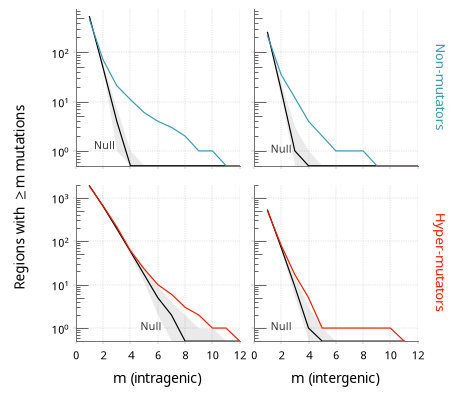

In [5]:
# --- style (ggplot linewidths are in mm-ish units: 1 lwd = 72.27/25.4 * 72/96 pt) ---
LW = 72.27 / 25.4 * 72 / 96
MM_PT = 72.27 / 25.4                     # ggplot text size (mm) -> pt
pal = ['#3B9AB2', '#78B7C5', '#EBCC2A', '#E1AF00', '#F21A00']

for f in ['NotoSans-Regular.ttf', 'NotoSans-Bold.ttf']:
    for d in [Path.home() / 'Library/Fonts', Path('/usr/share/fonts/truetype/noto'), Path('/Library/Fonts')]:
        if (d / f).exists():
            font_manager.fontManager.addfont(str(d / f))
mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Noto Sans', 'DejaVu Sans'],
    'mathtext.fontset': 'custom', 'mathtext.rm': 'Noto Sans', 'mathtext.it': 'Noto Sans', 'mathtext.cal': 'Noto Sans', 'mathtext.fallback': 'stixsans',
    'axes.linewidth': 0.3 * LW, 'axes.edgecolor': 'grey',
    'xtick.color': '#666666', 'ytick.color': '#666666',
    'xtick.labelcolor': 'black', 'ytick.labelcolor': 'black',
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'xtick.major.width': 0.1 * LW, 'ytick.major.width': 0.1 * LW,
    'axes.labelsize': 10,
    'pdf.fonttype': 42,
})
GRID = dict(color='#999999', linestyle=(0, (4, 4)), linewidth=0.1 * LW)
AXIS_GREY = '#666666'

def log_ticks(ax, ymin, ymax):
    """annotation_logticks(sides='l'): ticks drawn inside the panel from the left edge."""
    trans = ax.get_yaxis_transform()   # x in axes coords, y in data coords
    fig_w = ax.get_window_extent().width / ax.figure.dpi * 2.54  # panel width in cm
    for e in range(int(np.floor(np.log10(ymin))), int(np.ceil(np.log10(ymax))) + 1):
        for k in range(1, 10):
            y = k * 10.0 ** e
            if not ymin <= y <= ymax:
                continue
            length_cm = 0.3 if k == 1 else (0.2 if k == 5 else 0.1)
            ax.plot([0, length_cm / fig_w], [y, y], transform=trans, color='black', lw=0.2 * LW,
                    solid_capstyle='butt', clip_on=False)

def multiplicity_panel(ax, key, ymax, xmax_obs, color, null_xy, show_xlabels, show_ylabels, xlabel):
    d = null[key]
    d = d[(d.mult > 0) & (d.mult <= xmax_obs)]
    ymin = 0.5
    floor = lambda y: np.where(y > 0, y, ymin)   # zeros are drawn on the bottom edge, as -Inf is in ggplot
    ax.set_yscale('log')
    ax.set_xlim(0, 12); ax.set_ylim(ymin, ymax)
    ax.fill_between(d.mult, floor(d.p5), floor(d.p95), color='#333333', alpha=0.1, lw=0)
    ax.plot(d.mult, floor(d['median']), color='black', lw=0.4 * LW)
    ax.plot(d.mult, floor(d.obs), color=color, lw=0.4 * LW)
    ax.text(*null_xy, 'Null', fontsize=2.5 * MM_PT, color='#333333', ha='center', va='center')

    ax.xaxis.set_major_locator(FixedLocator(range(0, 13, 2)))
    ax.yaxis.set_major_locator(FixedLocator([10.0 ** e for e in range(0, 4)]))
    ax.yaxis.set_minor_locator(FixedLocator([]))
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda y, _: f'$10^{{{int(round(np.log10(y)))}}}$'))
    ax.grid(True, which='major', **GRID)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color(AXIS_GREY)
    ax.tick_params(colors=AXIS_GREY, labelcolor='black', pad=2)
    if not show_xlabels:
        ax.tick_params(axis='x', labelbottom=False)
    else:
        ax.set_xlabel(xlabel, labelpad=4)
    if not show_ylabels:
        ax.yaxis.set_major_formatter(NullFormatter())
    log_ticks(ax, ymin, ymax)

fig = plt.figure(figsize=(4.7, 4))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.15], left=0.17, right=0.98, bottom=0.14, top=0.97, wspace=0.12, hspace=0.12)
panels = [
    # key, row, col, ymax, xmax, colour, 'Null' label position (as in the R version)
    (('intragenic', 'non-mutators'), 0, 0, 0.75e3, 12, pal[0], (2.1, 1.3)),
    (('intergenic', 'non-mutators'), 0, 1, 0.75e3, 12, pal[0], (2.0, 1.1)),
    (('intragenic', 'mutators'),     1, 0, 2e3,    12, pal[4], (5.5, 1.1)),
    (('intergenic', 'mutators'),     1, 1, 2e3,    11, pal[4], (2.0, 1.1)),
]
axes = {}
for key, row, col, ymax, xmax, color, null_xy in panels:
    ax = fig.add_subplot(gs[row, col])
    multiplicity_panel(ax, key, ymax, xmax, color, null_xy,
                       show_xlabels=row == 1, show_ylabels=col == 0, xlabel=f'm ({key[0]})')
    axes[row, col] = ax

for row, (label, color) in enumerate([('Non-mutators', pal[0]), ('Hyper-mutators', pal[4])]):
    lab = fig.add_subplot(gs[row, 2]); lab.axis('off')
    lab.text(0, 0.5, label, rotation=270, color=color, fontsize=3.4 * MM_PT, ha='left', va='center', transform=lab.transAxes)

fig.supylabel(r'Regions with $\geq$m mutations', fontsize=10, x=0.03)

fig.savefig(PLOTS / 'multiplicity_vs_null.png', dpi=300)
fig.savefig(PLOTS / 'PDF' / 'multiplicity_vs_null.pdf')
plt.show()